# Summary — pairs trading on INTC/AMD and KO/PEP

This is the short notebook to read first. I ran the same pre-registered pipeline on INTC/AMD (my project's pair) and on KO/PEP (the brief's textbook pair, as a second-pair extension). **Nothing is computed here:** the charts are figures already saved by the detailed notebooks, and every number is copied from their outputs and from `EXPERIMENTS.md`.

**What I conclude, in short.**
- Neither pair is cointegrated in-sample, and both lose out-of-sample.
- INTC/AMD loses everywhere.
- KO/PEP earns on the whole in-sample grid and still loses out-of-sample.
- A good in-sample result was not evidence of a lasting relationship on either pair.

| Topic | Detailed notebook |
|---|---|
| Code check on synthetic pairs | `00_pipeline_check` |
| Phase 1 — data | `01_data` |
| Phase 2 — spread, signal, IS grid; single OOS run | `02_signal`, `02c_oos` |
| Phase 3 — stability | `03_stability` |
| Phase 4 — short interest | `04_short_interest` |
| Phase 5 — bootstrap and look-elsewhere test | `05_simulation` |
| Extension — Kalman hedge ratio | `06_kalman` |
| Extension — second pair, KO/PEP | `appendix_kopep` |

Rules I followed throughout:
- the IS/OOS split was fixed by rule before looking at prices (INTC/AMD: IS 1980–2012, OOS 2013–2026);
- every configuration was pre-registered, and each OOS was run once;
- signal at the close of day t, position from day t+1;
- costs of 5 bp per leg.

In [1]:
from pathlib import Path

from IPython.display import Image, display

FIGURES = Path("..") / "reports" / "figures"


def show(name: str) -> None:
    """Display a figure already saved by a detailed notebook."""
    display(Image(filename=FIGURES / f"{name}.png"))

## 1. Can I trust the code?

Before reading a negative result I wanted to know whether the pipeline could find a positive one. I tested it on synthetic pairs where I know the answer:
- **Mean-reverting (OU) spread:** it recovers β = 0.800 (true 0.8) and earns a net Sharpe of 1.89 IS and 1.92 OOS.
- **Random-walk spread:** it finds no cointegration (Engle–Granger p = 0.62).

This rules out gross errors. It does not prove the pipeline can detect a *weak* relationship: the positive control is easy (half-life 10 days, one seed).

## 2. INTC/AMD — is there a relationship? (Phases 1–2)

- **Day by day, yes:** the daily returns are correlated (0.48 in-sample).
- **In price levels, no:**
  - the INTC/AMD ratio has no stable level (from 0.018 in 1984 to 13.75 in 2015, and 0.17 today);
  - on log prices with β = 1.047, Engle–Granger gives p = 0.975, and the spread's half-life is about 27 years.

The rolling z-score is a trap: it *looks* mean-reverting because it is re-centred every 60 days, exactly like the z-score of a pure random walk (right panel).

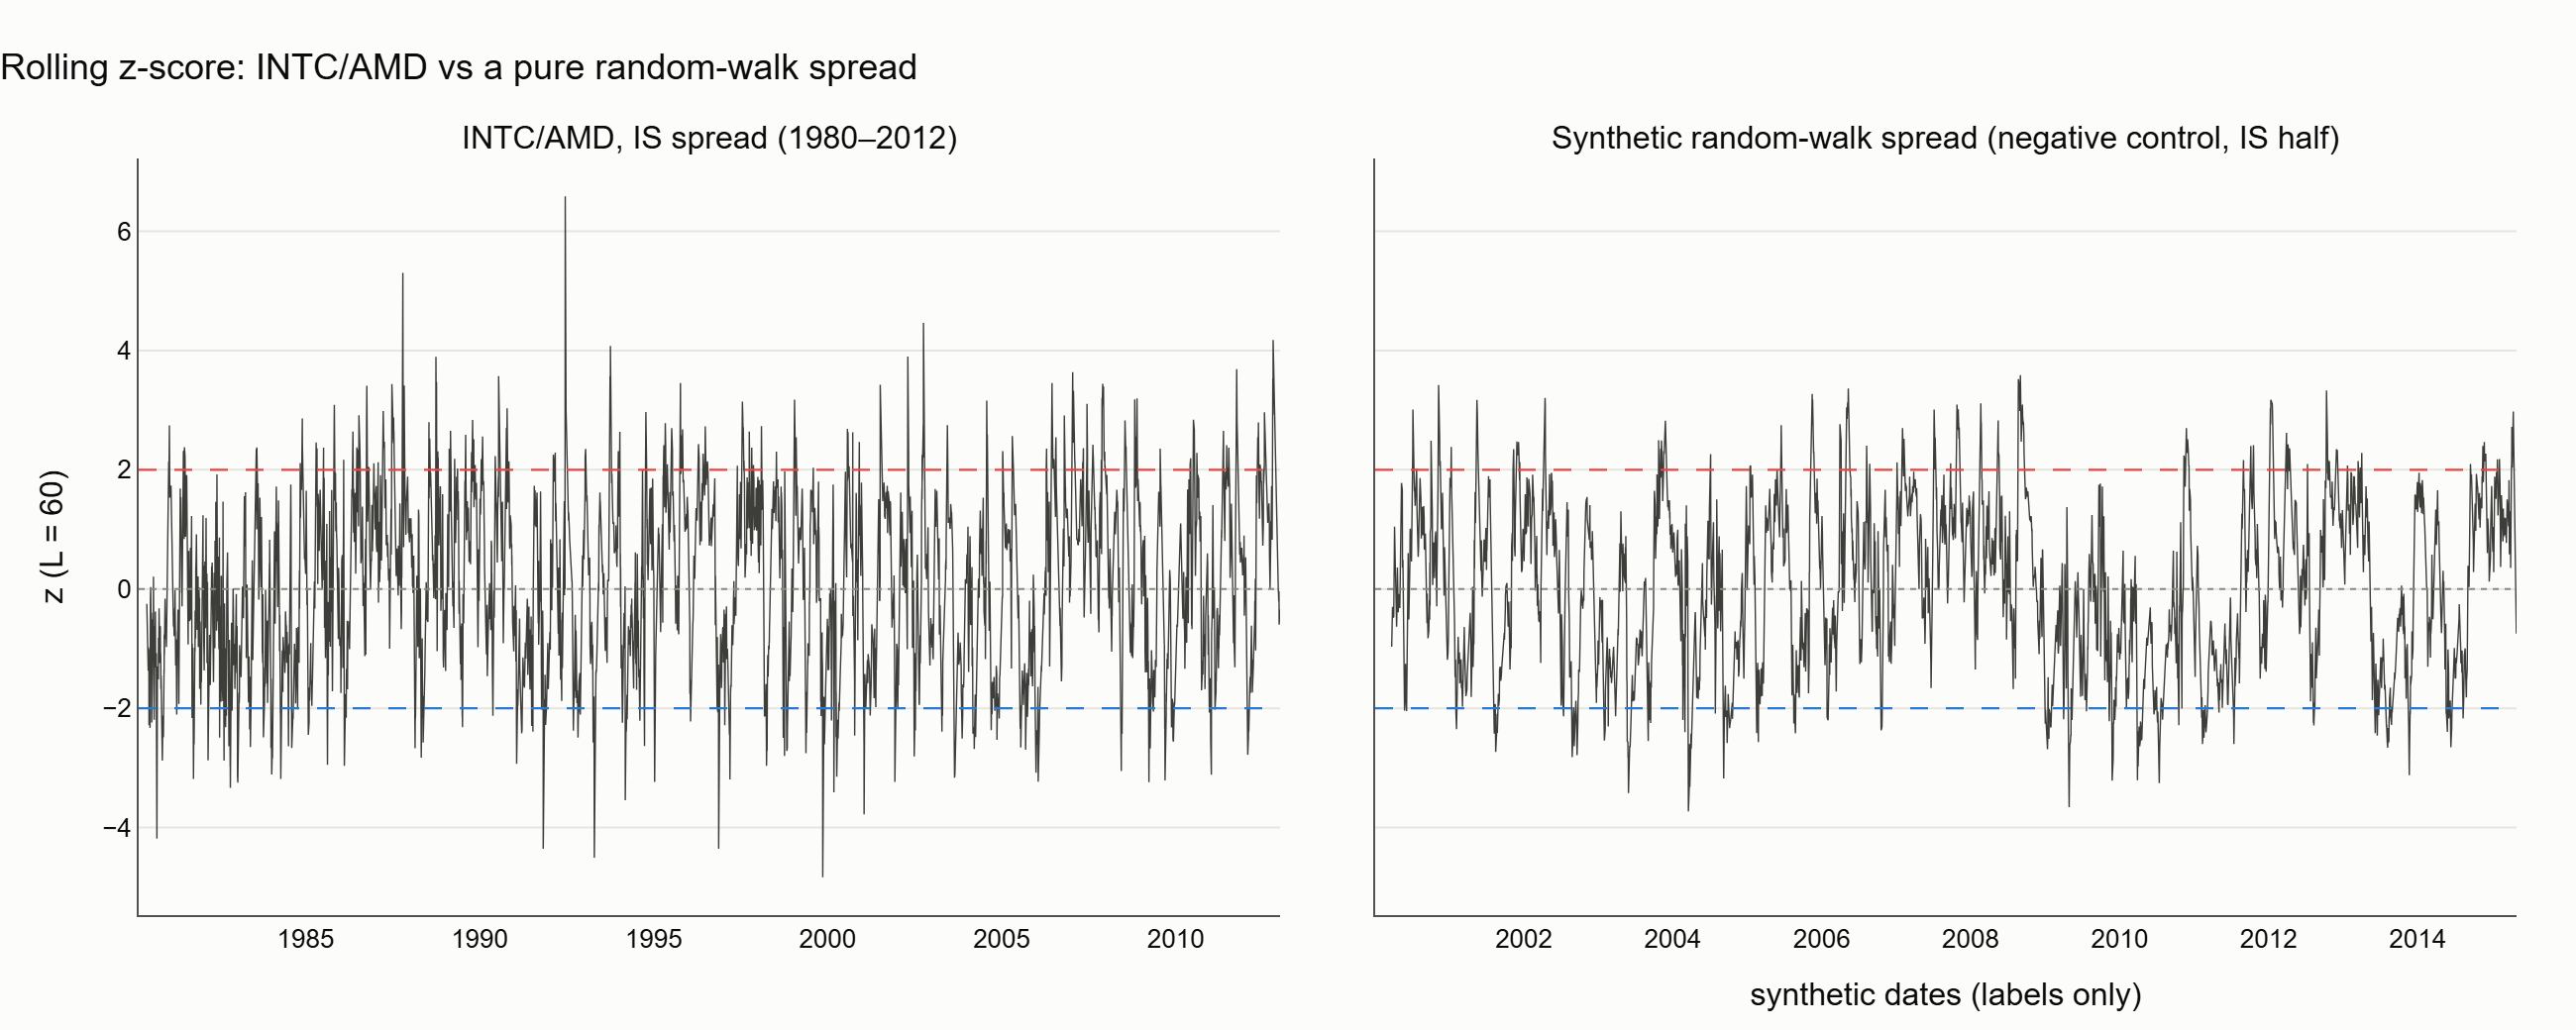

In [2]:
show("02h_zscore_intc_amd_vs_random_walk")

I fixed the main configuration (entry ±2.0, L = 60) before running anything. Its net Sharpe is **−0.27 in-sample**.
- All 9 cells of the grid lose net of costs, so this is not a bad parameter choice.
- It loses gross of costs too, so costs are not the cause.
- The brief's version on price levels loses as well.

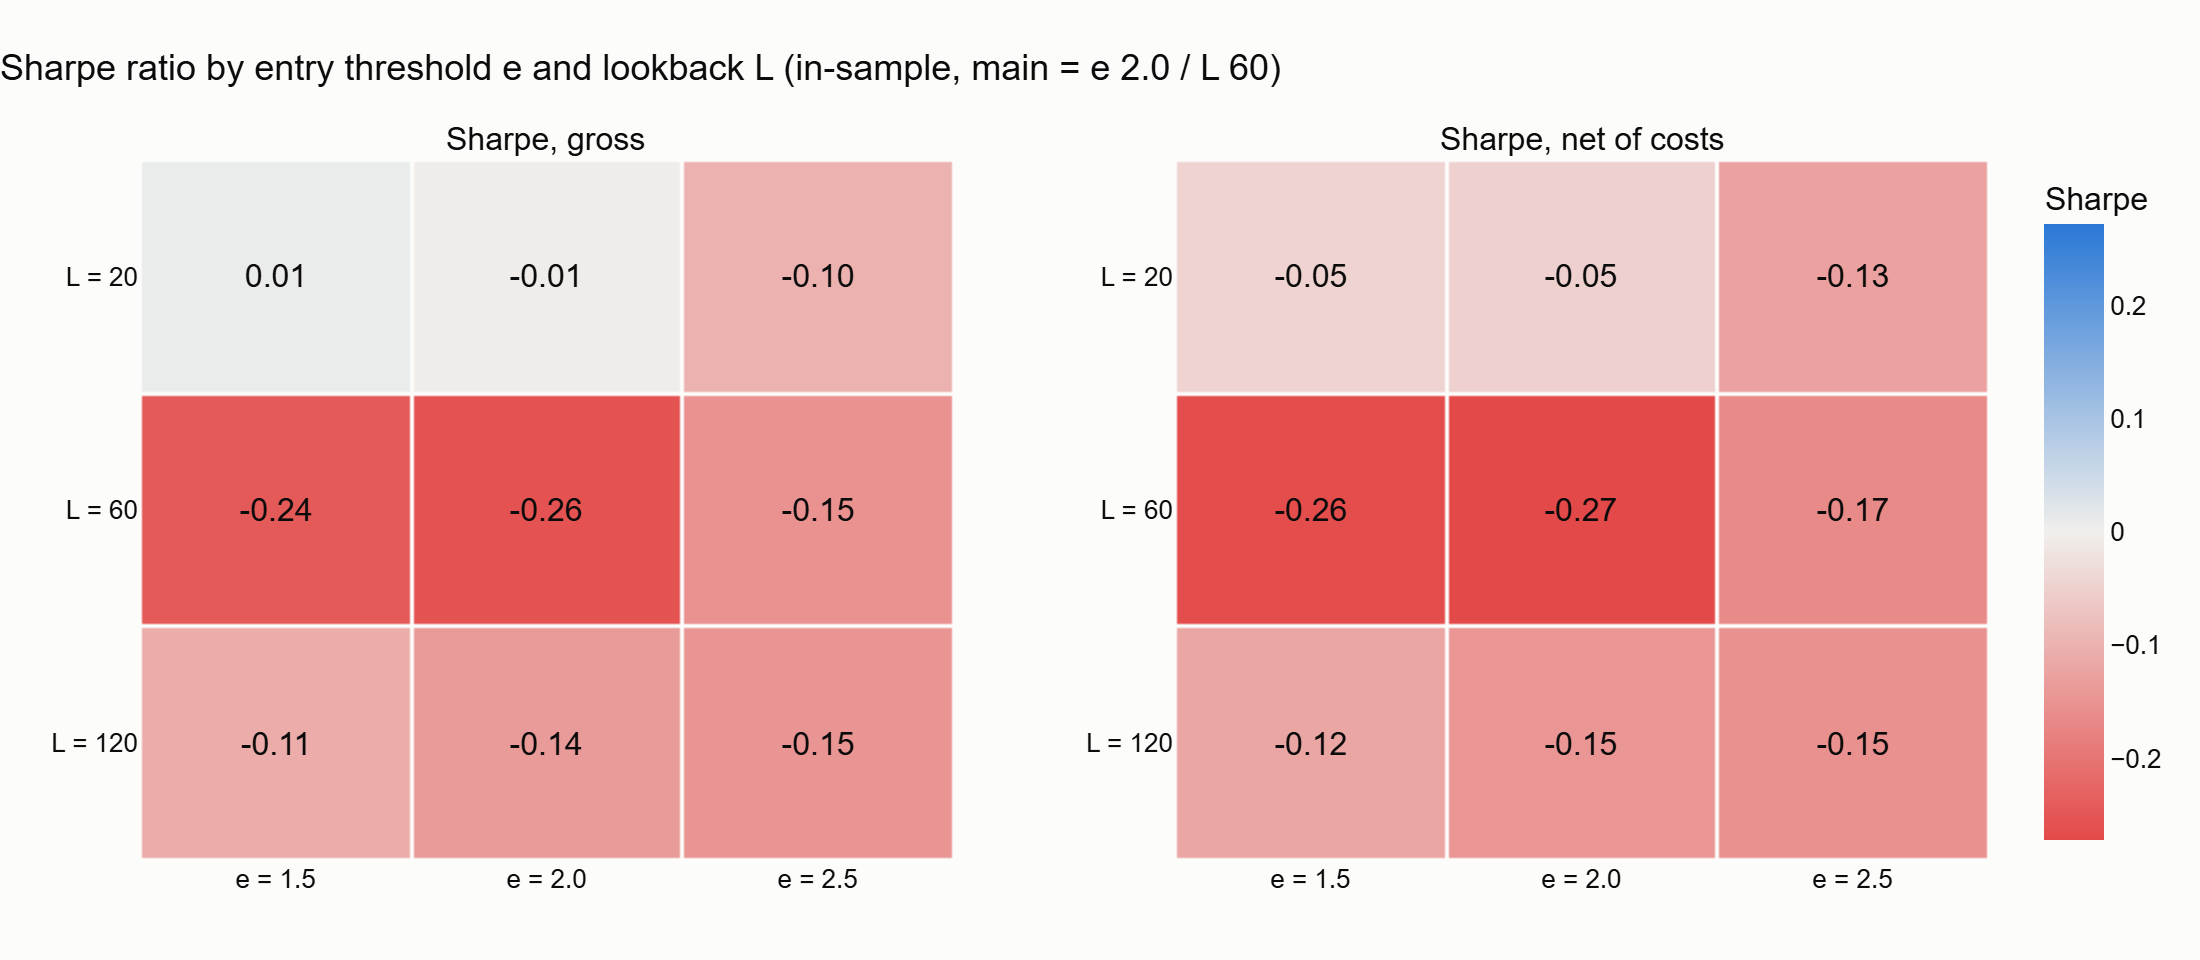

In [3]:
show("02d_sharpe_heatmap_is")

The single OOS run, with β frozen, gives a net Sharpe of **−0.18** and a max drawdown of −82%.

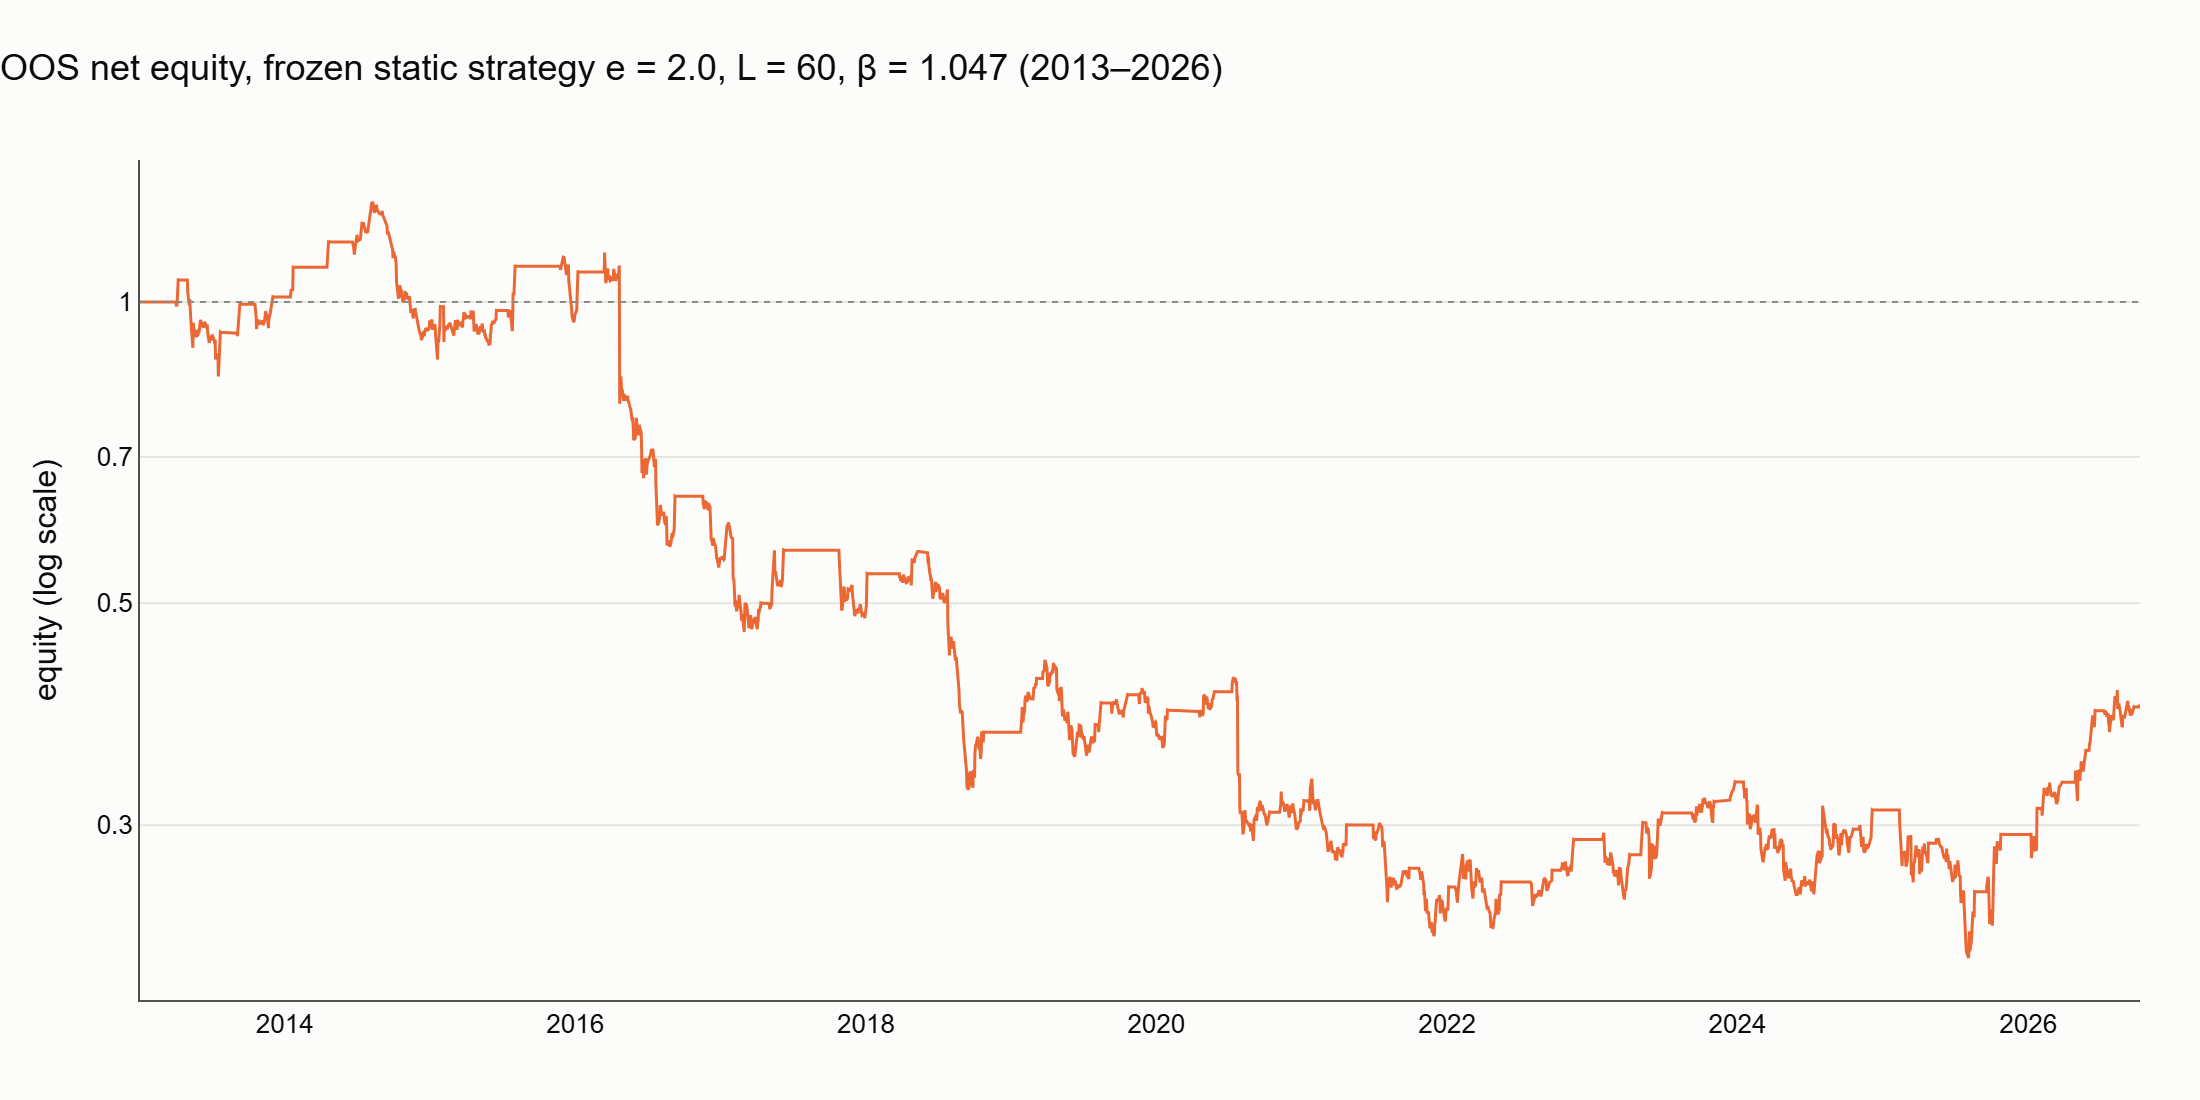

In [4]:
show("02f_equity_oos")

## 3. Why does it lose? (Phase 3)

- The one-year rolling β has a median of 0.39. The static β (1.047) is above its 95th percentile.
- With that much AMD in the hedge, the daily change of the spread has correlation −0.75 with AMD's return. Each trade is mostly a contrarian bet on AMD, which trends for years.
- Splitting days by relationship strength (rolling ADF) does not separate the results: Welch p = 0.88.

I read this as a diagnosis that fits the data, not a proof.

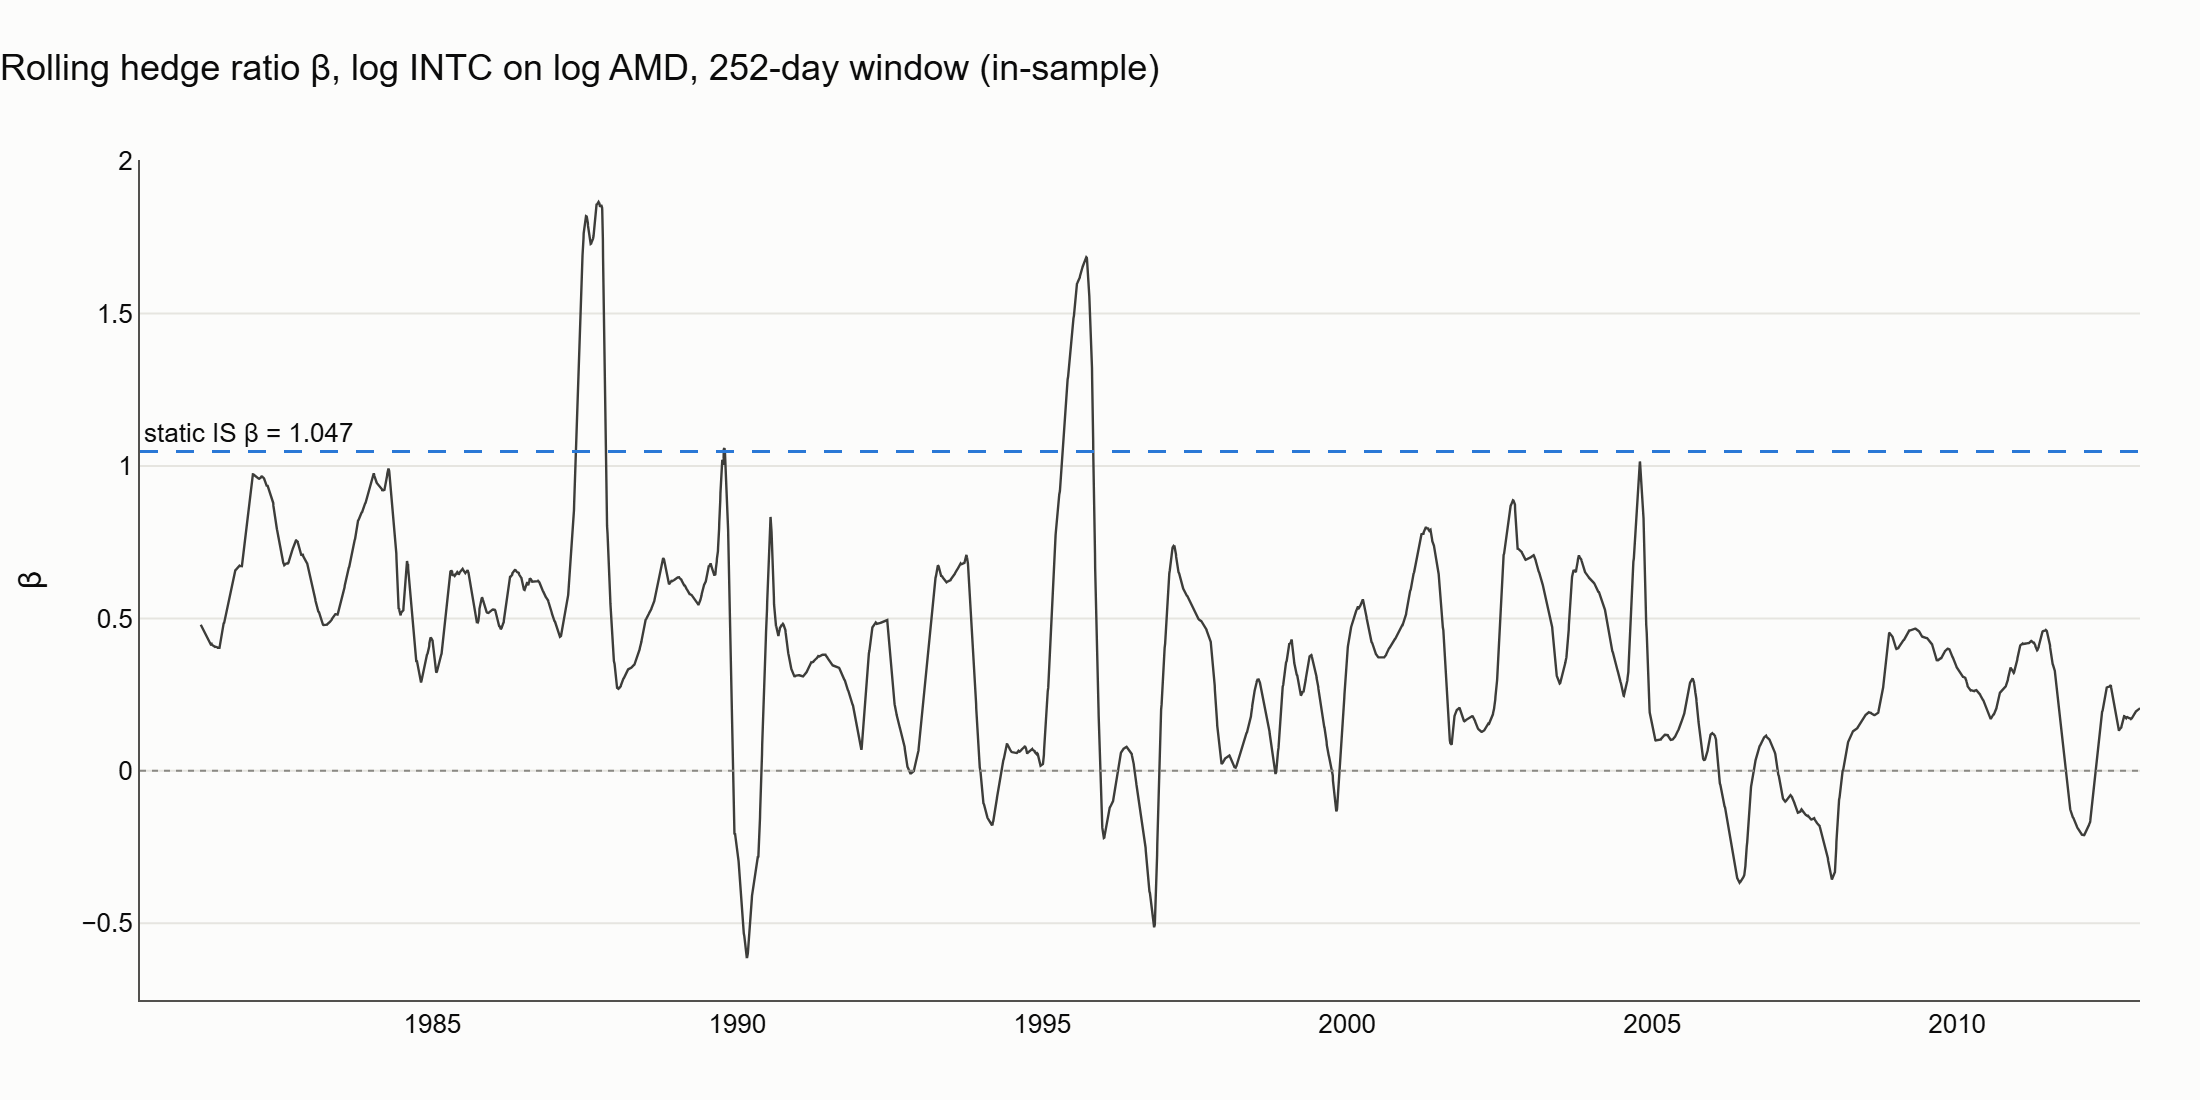

In [5]:
show("03a_rolling_beta_is")

## 4. Short interest (Phase 4, INTC/AMD only)

I pre-registered an alignment to the publication date, to avoid look-ahead, and with it none of the 5 tests is significant. On reflection that was the wrong choice for this question. It compares the spread move with positions measured about 7 business days earlier, so it is neither contemporaneous nor usable in real time.

With the natural alignment for a descriptive question, the settlement date, relative short interest (INTC − AMD) did move with the spread:
- ρ = 0.58, p = 0.004;
- this is still below the Bonferroni threshold over all 10 correlations I computed (0.005).

I take it as a real association in this one year (23 points), not as a trading signal.

Phase 4 was not part of the KO/PEP appendix, which I pre-registered as a test of the Phase 1–2 pipeline; when I later added Phases 3 and 5 as diagnostics, I did not add it.

## 5. Is the real result different from "no long-run link"? (Phase 5)

I used a joint block bootstrap instead of an OU process, because Phase 2 found no mean reversion to simulate. The paths keep the two stocks' daily co-movement within 20-day blocks but have no link beyond.
- **OOS:** the real Sharpe sits at the 21st percentile. I read this as absence of evidence, not proof: the null range is wide (5th–95th percentile −0.39 to 0.46).
- **IS:** the real Sharpe is at the 2.8th percentile, worse than the null, because AMD's multi-year trends last longer than the blocks.

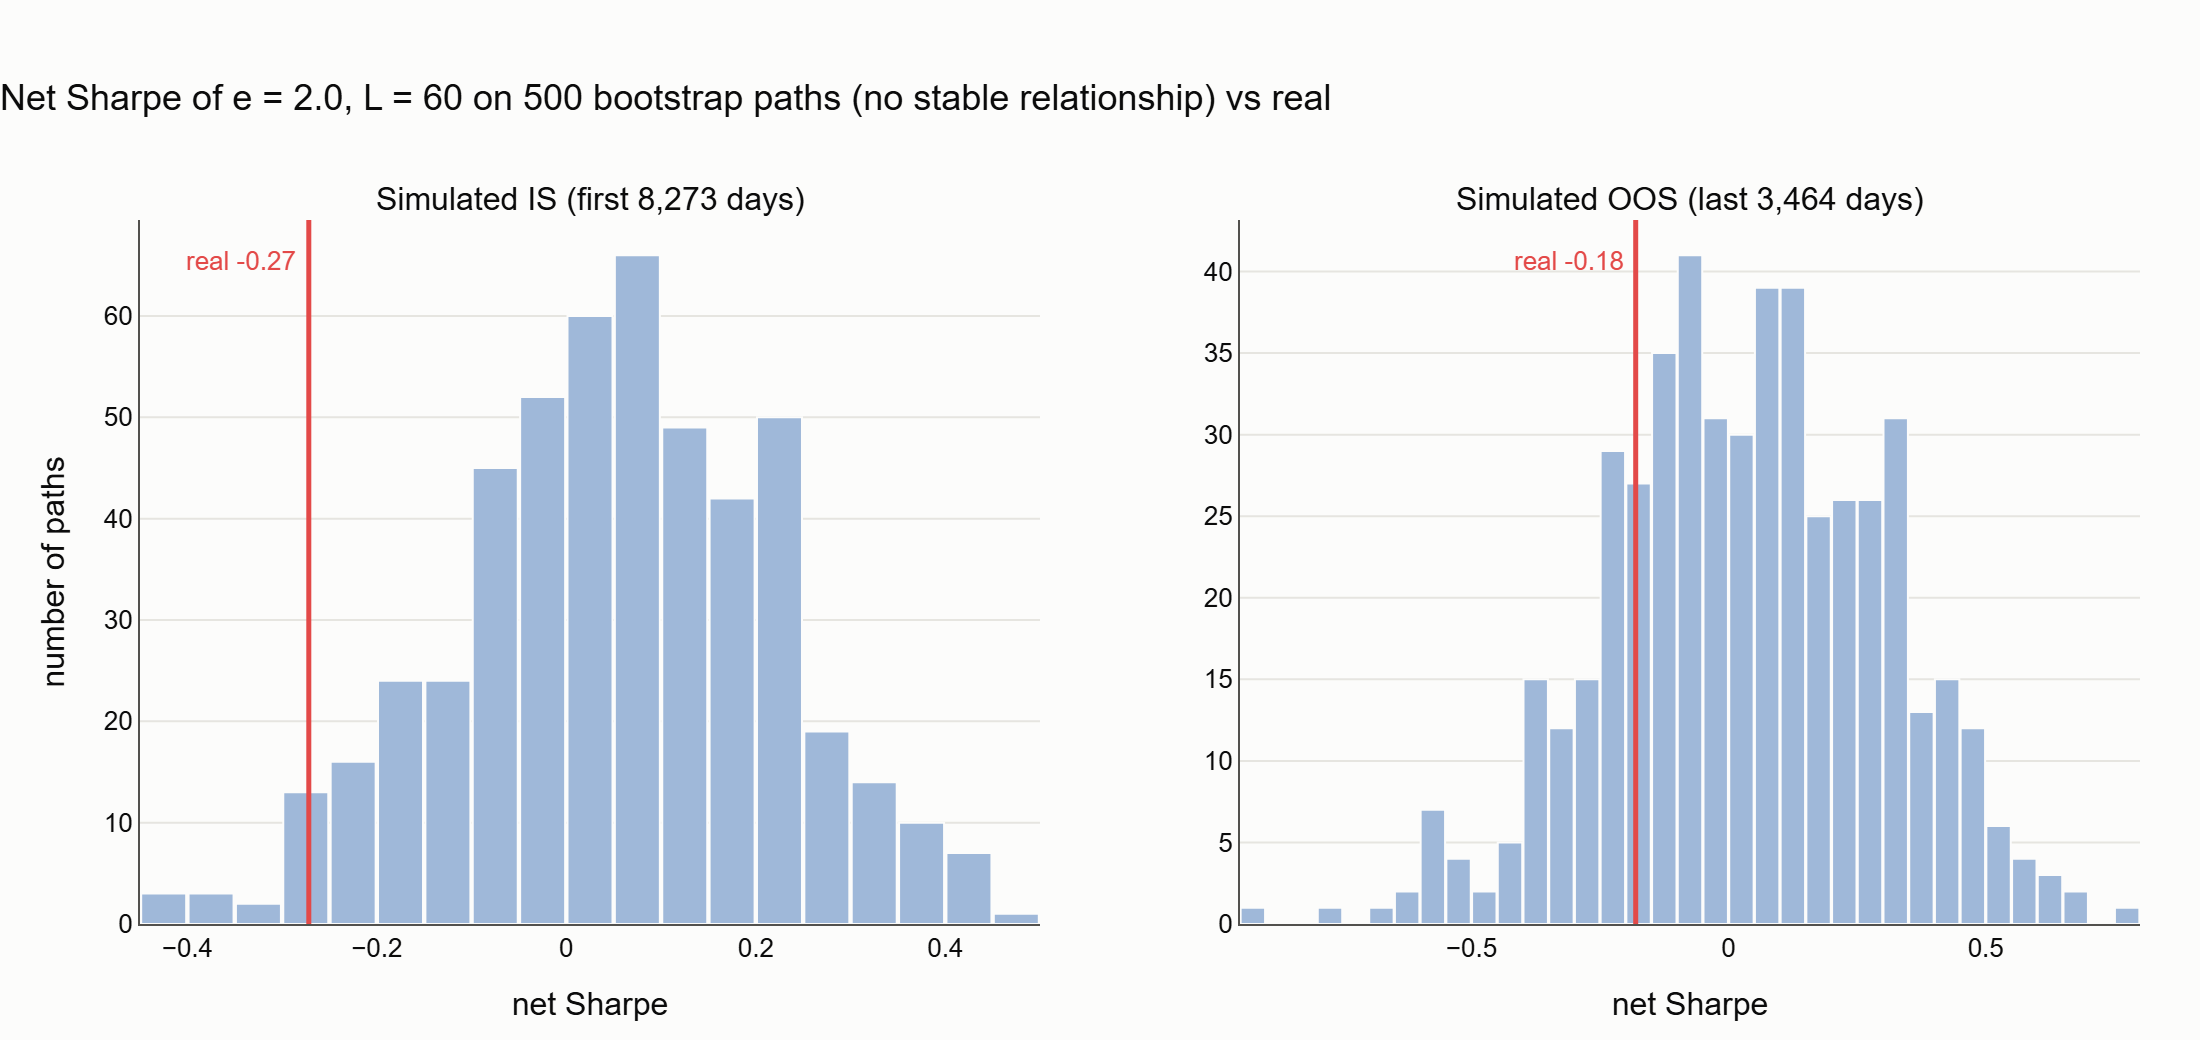

In [6]:
show("05a_sharpe_bootstrap_vs_real")

**Look-elsewhere: a general lesson.** On the price charts, 1997–2004 looked like a period where the two stocks were linked; it is not cointegrated (p = 0.51). The broader point: in 78.5% of null histories at least one of ~39 eight-year windows passes Engle–Granger at 5%. Searching a long history for a good-looking period finds one by chance.

## 6. Extension — Kalman hedge ratio (INTC/AMD only)

I chose this extension because it tests the Phase 3 diagnosis directly. The hyperparameters come from the literature, and I pre-registered the design before the first OOS run. Net Sharpe is +0.25 IS and **+0.07 OOS**, with an approximate 95% interval of −0.46 to +0.60.

My honest reading is that it does **not** confirm the diagnosis:
- With a local β around 0.2, the Kalman spread moves almost entirely with INTC: the correlation of its daily change with INTC's return is ≈ 0.94 OOS. It swaps a bet on AMD for a bet on INTC.
- Its in-sample Sharpe comes from 1981–1991 only.
- The OOS is not blind to my declared prior knowledge: I knew AMD outperformed after 2015, and a lower β mechanically reduces that exposure.

What it does show is that, whatever hedge ratio I use, this "pair" is dominated by one stock.

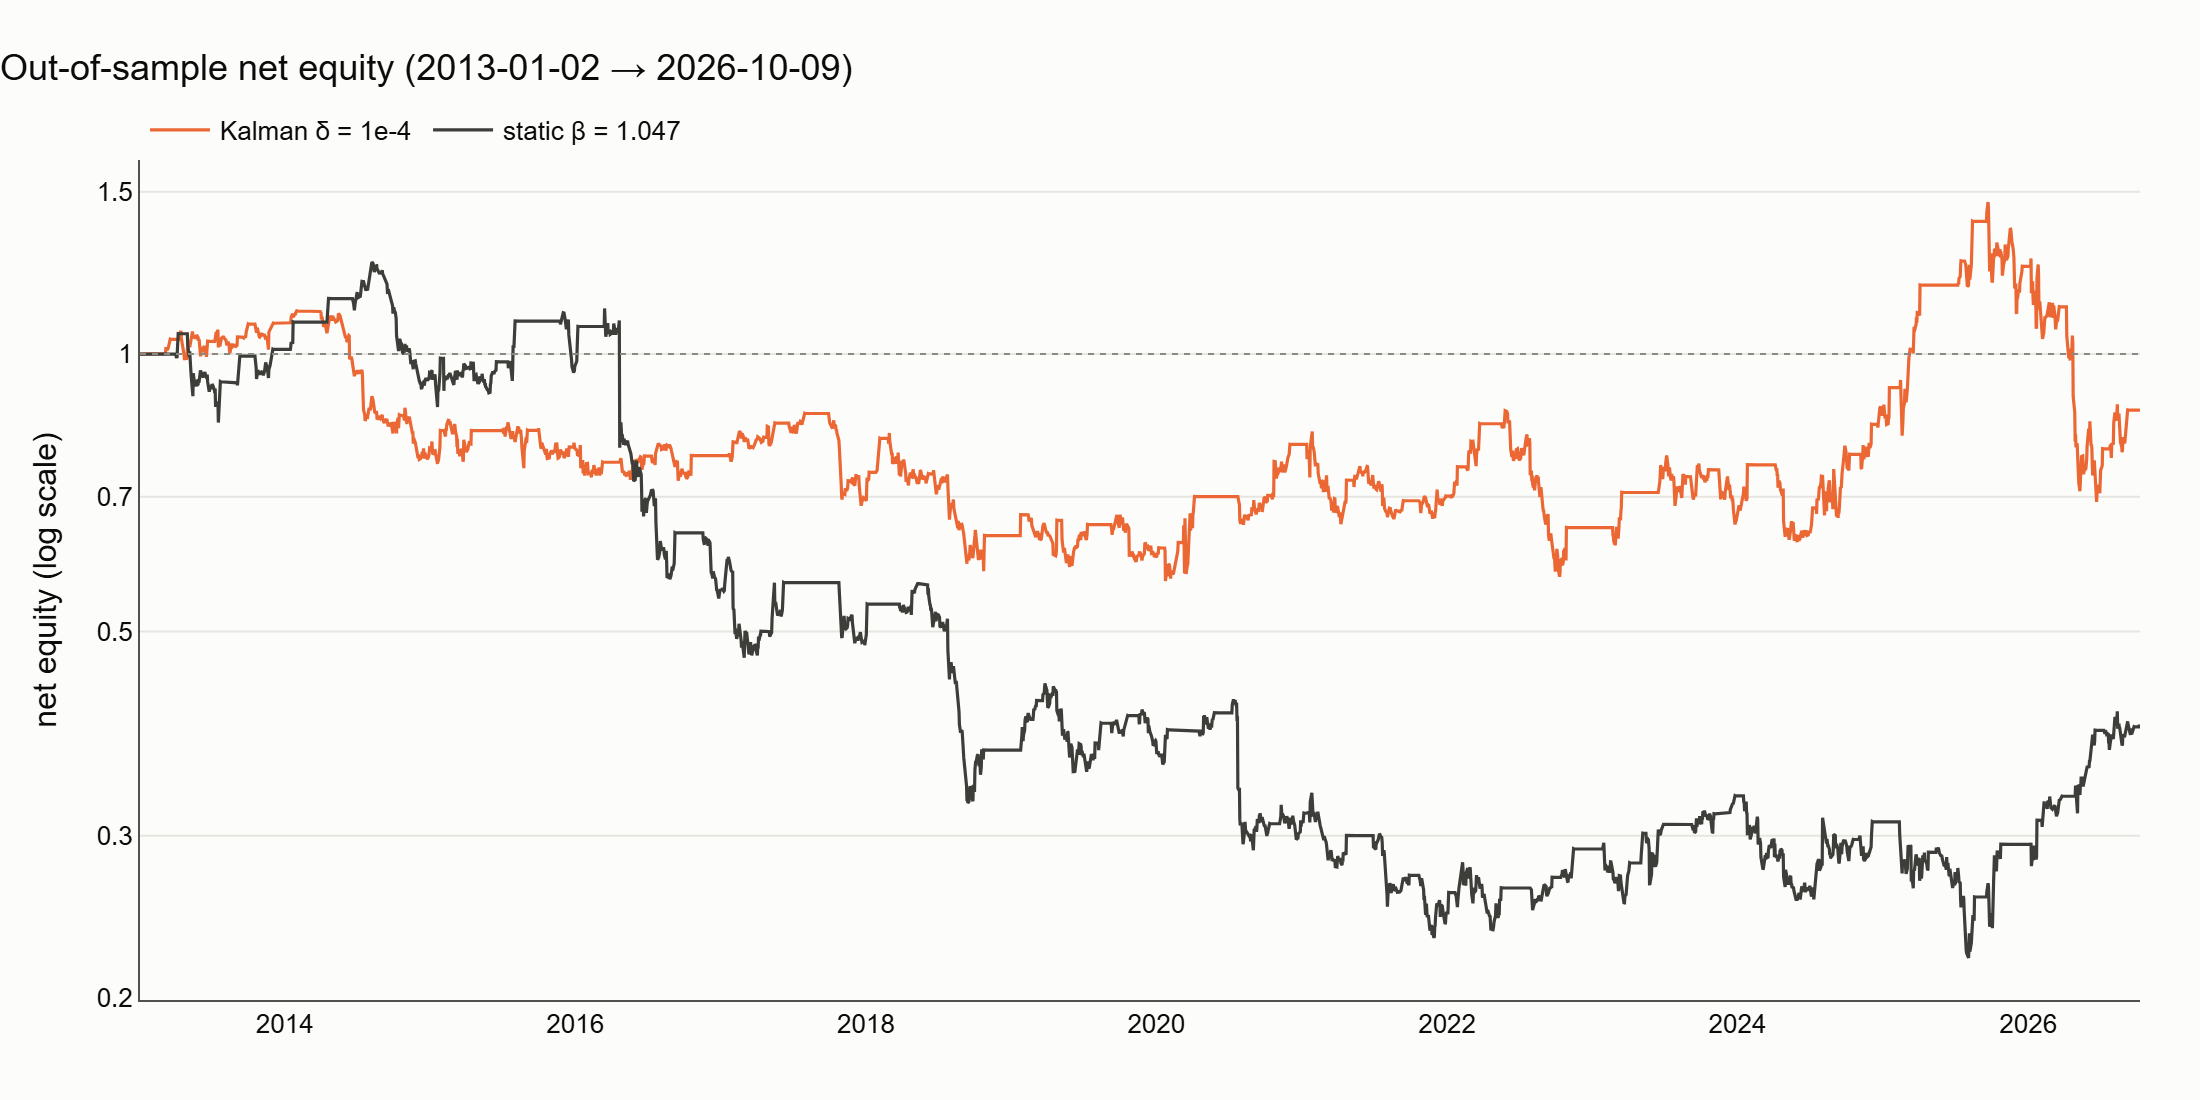

In [7]:
show("06c_equity_kalman_vs_static_oos")

## 7. INTC/AMD vs KO/PEP, phase by phase

| | INTC / AMD | KO / PEP |
|---|---|---|
| In-sample / out-of-sample | 1980–2012 / 2013–2026 | 1972–2009 / 2010–2026 |
| **Phase 2** — β (log prices, IS), R² | 1.047, 0.15 | 0.981, 0.975 |
| Engle–Granger p (IS) | 0.975 | 0.45 |
| Half-life of the spread (IS) | ≈ 27 years | ≈ 1.5 years |
| Net Sharpe IS, main configuration | −0.27 | 0.57 |
| IS grid, 9 configurations, net Sharpe | all negative (−0.27 to −0.05) | all positive (0.33 to 0.90) |
| Net Sharpe OOS, single run, β frozen | −0.18 | −0.21 |
| **Phase 3** — rolling β median (IS) vs static β | 0.39 vs 1.047 | 0.70 vs 0.98 |
| Weak-relationship days (IS); weak vs strong, Welch p | 87%; p = 0.88 | 69%; p = 0.21 * |
| **Phase 4** — short interest | association at settlement dates (section 4) | not run (outside the appendix scope) |
| **Phase 5** — percentile of real Sharpe in the bootstrap null, IS / OOS | 2.8th / 21st | 94th / 1.8th * |
| **Extension** — Kalman, net Sharpe IS / OOS | +0.25 / +0.07 | not run (would follow its OOS) |

\* For KO/PEP I decided on Phases 3 and 5 after seeing its results, to explain them, so I treat them as diagnostics, not tests.

**What the comparison taught me:**
- KO/PEP had everything that looks reassuring in-sample: an R² of 0.975, a half-life of 1.5 years instead of 27, and a positive Sharpe in every cell of the grid. It still lost out-of-sample.
- The bootstrap explains why. On KO/PEP the null itself earns in-sample (median 0.32), because the two stocks' short-term co-movement is enough for this strategy, so the real 0.57 is not special.
- On both pairs, only the single OOS run told the truth.

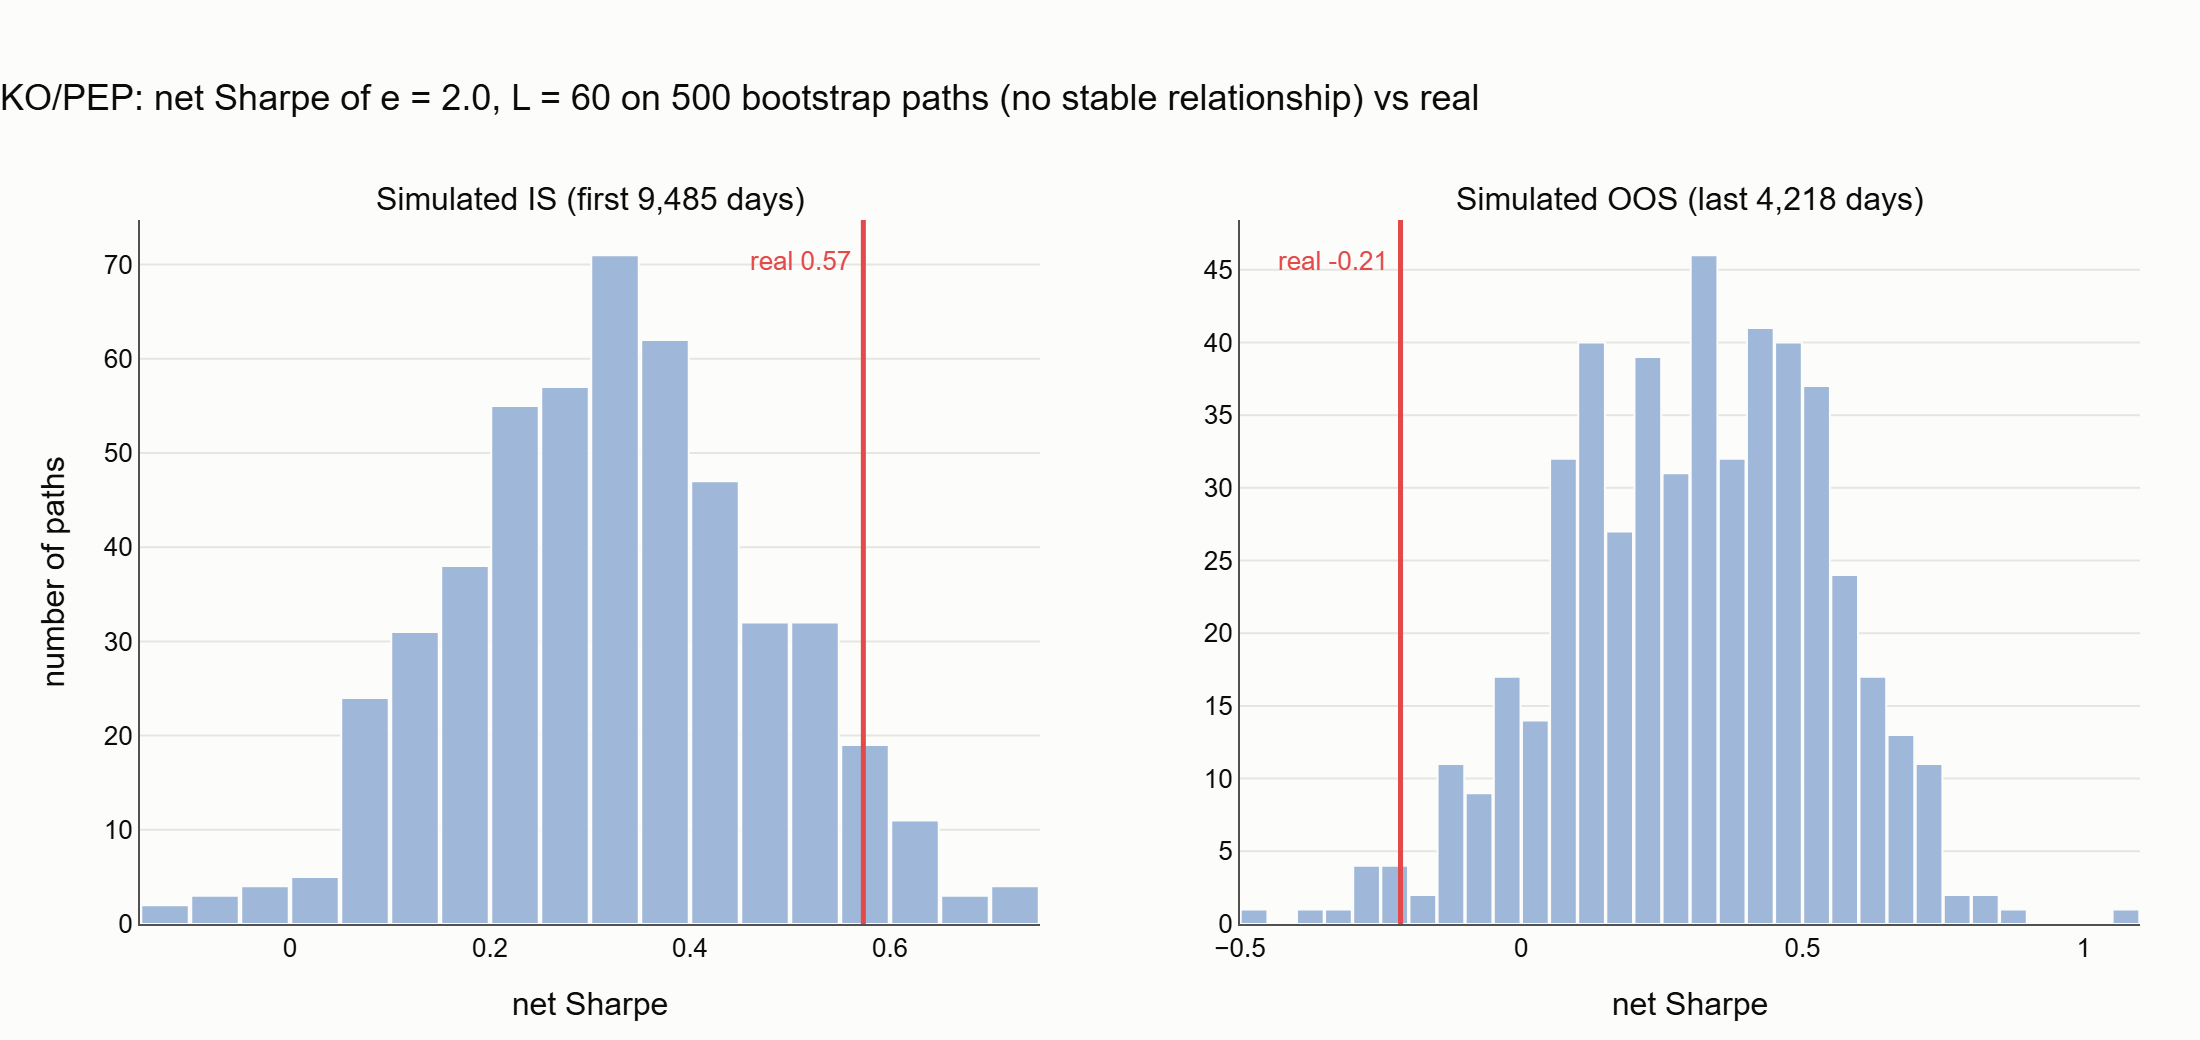

In [8]:
show("appx_i_kopep_sharpe_bootstrap_vs_real")

## 8. What I am confident about, and what I am not

**Confident:**
- neither pair shows cointegration in-sample, and the INTC/AMD loss holds across the grid and on price levels;
- the OOS results were run once, with everything frozen.

**Less sure:**
- the AMD-bet diagnosis fits the data but is not proven;
- the Phase 4 association rests on 23 points from one year;
- the synthetic controls show the code works on an easy case, not on a weak relationship.

**Declared limitations:**
- short-borrow costs and the Kalman's rebalancing costs are not modelled;
- the first IS trade inherits the signal state from before the evaluation window (one trade; the OOS starts flat);
- each pre-registration was committed together with its results, so the git history alone cannot prove the order (the timestamps are in `EXPERIMENTS.md`).

**All attempts:**
- INTC/AMD: 14 IS backtests, 2 OOS runs, 2 simulation runs (the look-elsewhere run includes one backtest on the real 1997–2004 window);
- KO/PEP: 9 IS backtests, 1 OOS run, 1 simulation run;
- 2 synthetic control runs.